In [1]:
import json 
import pandas as pd 
import seaborn as sns 
import numpy as np
import glob
import matplotlib.pyplot as plt 
import matplotlib.patches as mpatches
from matplotlib.markers import MarkerStyle
from matplotlib.patches import Ellipse
from matplotlib.colors import to_rgba
import scipy.stats
from sklearn import metrics
import pickle
import sys

from config import llm_review_path, supp_table_path, figure_path_2, figure_path, home_path

sys.path.insert(1, home_path) 
from common_functions import entropy, mean_confidence_interval, format_p, read_fasta, sort_dict_by_value

In [2]:

data_output_path = llm_review_path + "source_data_csvs/"


In [3]:
## plotting definitions 
rev_path = f"{home_path}singh/nlp_review/revisions/"



green_1 = "#357847"
coral_1 = "#E39695"
dark_blue_1 = "#2B2D42"
dark_red_1 = "#A3320B"
light_blue_1 = "#0C7489"
orange_1 = "#f5a60a"


ur_50_color = dark_red_1
ur_90_color = "seagreen"
ur_100_color = "dodgerblue"
bfd_color = "#ff7b00"

all_models = [
    "progen2_bfd",
    "progen2_medium",
    "progen2_large",
    "carp_640M",
    "carp_76M", 
    "carp_38M",
    "carp_600k",
    "prott5_xl_bfd",
    "prott5_xl",
    "protbert_bfd",
    "protbert",
    "esm_1b",
    "esm_1_UR50",
    "esm_2_15B",
    "esm_2",
    "esm_2_35M",
    "esm_1v",
    "esm_2_650M",
    "esm_1_UR100",
    "esm_1_UR50D",
    "esm_1_85M",
    "esm_2_150M",
    "esm_2_8M",
    "esm_1_43M"
]

model_to_dataset_shorthand = {m : "UR50" for m in all_models}
model_to_dataset_shorthand["prott5_xl_bfd"] = "BFD"
model_to_dataset_shorthand["progen2_medium"] = "BFD+UR90"
model_to_dataset_shorthand["progen2_large"] = "BFD+UR90"
model_to_dataset_shorthand["protbert_bfd"] = "BFD"
model_to_dataset_shorthand["protbert"] = "UR100"
model_to_dataset_shorthand["esm_1_UR100"] = "UR100"
model_to_dataset_shorthand["esm_1v"] = "UR90"
model_to_dataset_shorthand["esm_1_UR50D"] = "UR50D"
model_to_dataset_shorthand["esm_1_UR50"] = "UR50S"

model_to_color = {m : ur_50_color for m in all_models}
model_to_color["prott5_xl_bfd"] = bfd_color
model_to_color["progen2_medium"] = ur_90_color
model_to_color["progen2_large"] = ur_90_color
model_to_color["progen2_bfd"] = bfd_color
model_to_color["protbert_bfd"] = bfd_color
model_to_color["protbert"] = ur_100_color
model_to_color["esm_1_UR100"] = ur_100_color
model_to_color["esm_1v"] = ur_90_color






In [4]:
SAVE_FIGS = False

def save_figure(fig, name, root_path = figure_path, save_svg = True):
    fig.savefig(root_path + name + ".png", bbox_inches = "tight")
    if save_svg:
        fig.savefig(root_path + name + ".svg", format="svg", dpi = 1200, bbox_inches = "tight")
        
def pickle_obj(obj, fn):
    with open(fn, "wb") as f:
        pickle.dump(obj, f)
    f.close()
    
regular_aas = ['P','S','L','A','V','G','T','E','R','Q','D','F','I','H','Y','N','K','C','W','M']

def augment_masked_df_with_site_entropy(df, limit_normal_aas = True, return_entropy = True):
    df["name"] = df["ref_aa"] + df["aa_pos"].astype(str) + df["token_str"]
    df = df.loc[df["token_str"].isin(regular_aas)]
    variant_to_s1 = {}
    variant_to_adj_prob = {}
    variant_to_site_entropy = {}
    for pos, sub_df in df.groupby("aa_pos"):
        v_to_adj_score = {}
        valid_prob_total = np.sum(sub_df["score"])
        for index, row in sub_df.iterrows():
            v_to_adj_score[row["name"]] = row["score"] / valid_prob_total
        
        sub_df["adj_score"] = sub_df["name"].apply(lambda x : v_to_adj_score[x])
        
        wt_val = sub_df.loc[sub_df["ref_aa"] == sub_df["token_str"]]
        assert len(wt_val) == 1
        wt_score = wt_val.iloc[0]["adj_score"]
        
        adj_prob_list = []
        for index, row in sub_df.iterrows():
            variant_to_s1[row["name"]] = np.log(row["adj_score"]) - np.log(wt_score)
            variant_to_adj_prob[row["name"]] = row["adj_score"] / valid_prob_total
            adj_prob_list.append(row["adj_score"] / valid_prob_total)
        ent_val = entropy(adj_prob_list)
        
        for name in sub_df["name"].values: variant_to_site_entropy[name] = ent_val

    if return_entropy:
        df["site_entropy"] = df["name"].apply(lambda x : variant_to_site_entropy[x])
            
    df["s1"] = df["name"].apply(lambda x : variant_to_s1[x])
    df["adj_score"] = df["name"].apply(lambda x : variant_to_adj_prob[x])
    
    df = df.set_index("name")
    return df


def p_val_to_stars(p):
    if p <= 0.001:
        return "***"
    if p <= 0.01:
        return "**"
    if p <= 0.05:
        return "*"
    return "ns"

In [5]:


corr_df = pd.read_csv(
    home_path + "singh/nlp_review/notebooks/final_notebooks/all_masked_model_DMS_correlation.csv",
    index_col = 0 
)

name_conversions = {"esm_1_43M_UR50S" : "esm_1_43M",  'esm_1_85M_UR50S': "esm_1_85M", "esm_1_UR50S" : "esm_1_UR50"}
corr_df = corr_df.rename(columns = name_conversions)
corr_entropy_df = pd.read_csv("../corr_entropy_df.csv", index_col  = 0)
corr_entropy_df["model"] = corr_entropy_df["model"].apply(lambda x : x if x not in name_conversions.keys() else name_conversions[x] )

new_dms_runs_new_models = pd.read_csv(rev_path + "scripts/DMS_data/results/new_models_217_dms_results.csv", index_col = 0)
new_dms_runs_new_models = new_dms_runs_new_models.drop(columns = "protbert_bfd") # did this one twice, once in previous and once in revisions

new_dms_entropy_new_models = pd.read_csv(rev_path + "scripts/DMS_data/results/new_models_217_dms_mutated_site_entropy.csv", index_col = 0)
new_dms_entropy_new_models = new_dms_entropy_new_models.drop(columns = "protbert_bfd") # did this one twice,  once in previous and once in revisions

new_dms_entropy_new_models.loc[new_dms_entropy_new_models.index.str.contains("Flynn")]


exp_map = {
    "A4D664_9INFA_Soh_CCL141_2019" : "A4D664_9INFA_Soh_2019",
    "A4_HUMAN_Seuma_2021" : "A4_HUMAN_Seuma_2022",
    "B3VI55_LIPST_Klesmith_2015" : "LGK_LIPST_Klesmith_2015",
    'CAPSD_AAV2S_Sinai_substitutions_2021' : "CAPSD_AAV2S_Sinai_2021",
    'CP2C9_HUMAN_Amorosi_abundance_2021' : "CP2C9_HUMAN_Amorosi_2021_abundance",
    'CP2C9_HUMAN_Amorosi_activity_2021' : "CP2C9_HUMAN_Amorosi_2021_activity" ,
    'DYR_ECOLI_Thompson_plusLon_2019' : "DYR_ECOLI_Thompson_2019",
    'GCN4_YEAST_Staller_induction_2018' : "GCN4_YEAST_Staller_2018",
    'MTH3_HAEAE_Rockah-Shmuel_2015' : "MTH3_HAEAE_RockahShmuel_2015",
    'NRAM_I33A0_Jiang_standard_2016' : "NRAM_I33A0_Jiang_2016",
    'P53_HUMAN_Giacomelli_NULL_Etoposide_2018' : "P53_HUMAN_Giacomelli_2018_Null_Etoposide",
    'P53_HUMAN_Giacomelli_NULL_Nutlin_2018' : "P53_HUMAN_Giacomelli_2018_Null_Nutlin",
    'P53_HUMAN_Giacomelli_WT_Nutlin_2018' :'P53_HUMAN_Giacomelli_2018_WT_Nutlin' ,
    'R1AB_SARS2_Flynn_growth_2022' : "R1AB_SARS2_Flynn_2022",
    'RL401_YEAST_Mavor_2016' : "RL40A_YEAST_Mavor_2016",
    'RL401_YEAST_Roscoe_2013' : "RL40A_YEAST_Roscoe_2013" ,
    'RL401_YEAST_Roscoe_2014' : "RL40A_YEAST_Roscoe_2014",
    'SRC_HUMAN_Ahler_CD_2019' : "SRC_HUMAN_Ahler_2019",
    'TPOR_HUMAN_Bridgford_S505N_2020' : "TPOR_HUMAN_Bridgford_2020",
    'VKOR1_HUMAN_Chiasson_abundance_2020' : "VKOR1_HUMAN_Chiasson_2020_abundance",
    'VKOR1_HUMAN_Chiasson_activity_2020' : "VKOR1_HUMAN_Chiasson_2020_activity"
}

exp_map = {v : k for (k,v) in exp_map.items()}
new_dms_runs_new_models = new_dms_runs_new_models.rename(index=exp_map)
new_dms_entropy_new_models = new_dms_entropy_new_models.rename(index = exp_map)

corr_df = corr_df.join(new_dms_runs_new_models)

models_using = [
    "progen2_bfd",
    "progen2_medium",
    "progen2_large",
    "carp_640M",
    "carp_76M", 
    "carp_38M",
    "carp_600k",
    "prott5_xl_bfd",
    "prott5_xl",
    "protbert_bfd",
    "protbert",
    "esm_1b",
    "esm_1_UR50",
    "esm_2_15B",
    "esm_2",
    "esm_2_35M",
    "esm_1v",
    "esm_2_650M",
    "esm_1_UR100",
    "esm_1_UR50D",
    "esm_1_85M",
    "esm_2_150M",
    "esm_2_8M",
    "esm_1_43M"
]


In [6]:
print(corr_df.columns)

corr_df = corr_df[models_using]

exp_to_max_corr = {}
exp_to_mean_corr = {}

# NaN indicates longer than 1022 AA 
# all_new_dms = all_new_dms.dropna()

gene_to_exp_ids = {}

for index, row in corr_df.iterrows():
    exp_to_max_corr[index] = np.max(row.values)
    exp_to_mean_corr[index] = np.mean(row.values)
    gene = "_".join(index.split("_")[:2])
    if gene in gene_to_exp_ids.keys():
        gene_to_exp_ids[gene].append(index)
    
    else:
        gene_to_exp_ids[gene] = [index]

old_fit_exps = pd.read_csv(supp_table_path + "entropy_optimal_training_experiments.csv")
set(old_fit_exps["experiment"].values)

# not actually using these 

Index(['esm_1_43M', 'esm_1_85M', 'esm_1b', 'esm_1_UR100', 'esm_1_UR50D',
       'esm_1_UR50', 'esm_1v', 'esm_2', 'esm_2_150M', 'esm_2_15B', 'esm_2_35M',
       'esm_2_650M', 'esm_2_8M', 'protbert', 'protbert_bfd', 'progen2_bfd',
       'carp_76M', 'prott5_xl_bfd', 'progen2_medium', 'carp_640M', 'carp_38M',
       'prott5_xl', 'progen2_large', 'carp_600k'],
      dtype='object')


{'A4D664_9INFA_Soh_CCL141_2019',
 'CALM1_HUMAN_Weile_2017',
 'ENV_HV1BR_Haddox_2016',
 'ESTA_BACSU_Nutschel_2020',
 'GFP_AEQVI_Sarkisyan_2016',
 'I6TAH8_I68A0_Doud_2015',
 'MK01_HUMAN_Brenan_2016',
 'MSH2_HUMAN_Jia_2020',
 'REV_HV1H2_Fernandes_2016',
 'SPG1_STRSG_Olson_2014',
 'SYUA_HUMAN_Newberry_2020',
 'TPK1_HUMAN_Weile_2017'}

In [7]:
hq_cutoff = 0.4

In [8]:
gene_to_representative_experiment = {}
for gene, exps in gene_to_exp_ids.items():
    valid_exps = []
    for gene_exp in exps:
        max_corr = exp_to_max_corr[gene_exp]
        if max_corr >= hq_cutoff:
            valid_exps.append(gene_exp)
            
    if len(valid_exps) == 0:
        continue 
        
    rep_exp = None 
    max_corr = float("-inf")
    
    for v_exp in valid_exps:
        mean_corr = exp_to_mean_corr[v_exp]
        if mean_corr > max_corr:
            max_corr = mean_corr
            rep_exp = v_exp
      
    gene_to_representative_experiment[gene] = rep_exp
    
# this is to be consistent w the named way  MAPLE was chosen in other notebook 
gene_to_representative_experiment["BLAT_ECOLX"] = "BLAT_ECOLX_Stiffler_2015"
EXPS_USING = set(gene_to_representative_experiment.values())


print("num EXPs using", len(EXPS_USING))



num EXPs using 49


In [9]:


corr_df = corr_df.loc[corr_df.index.isin(EXPS_USING)]


covered_exps = set(corr_entropy_df["experiment"].values)

corr_entropy_df = corr_entropy_df.loc[corr_entropy_df["experiment"].isin(EXPS_USING)]


model_to_entropy = {}

for index, row in corr_entropy_df.iterrows():
    exp = row["experiment"]
    model = row["model"]
    ent_val = row["average_site_entropy"]
    
    if model in model_to_entropy.keys():
        model_to_entropy[model][exp] = ent_val
        
    else:
        model_to_entropy[model] = {exp : ent_val}
        
corr_entropy_df = pd.DataFrame(model_to_entropy)
new_dms_entropy_new_models = new_dms_entropy_new_models.loc[new_dms_entropy_new_models.index.isin(covered_exps)]
corr_entropy_df = corr_entropy_df.join(new_dms_entropy_new_models)
corr_entropy_df = corr_entropy_df[models_using]

print(len(corr_entropy_df.columns))

for e in EXPS_USING:
    if e not in covered_exps:
        print("missing ", e)

24


1.313511423623943e-21


Text(0.5, 1.0, 'Different Model Architecture\nSimilar Training Dataset')

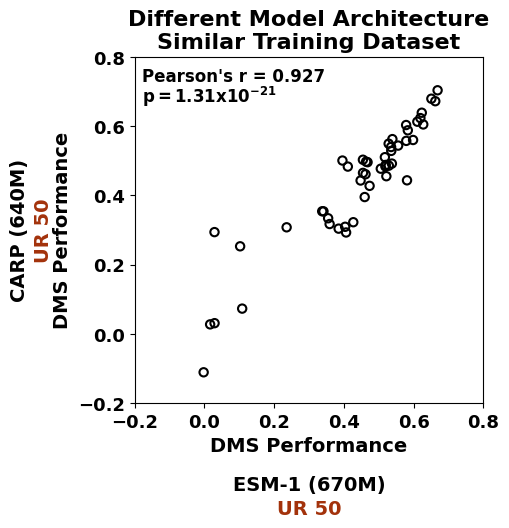

In [10]:
fig, ax = plt.subplots(figsize = (4.5,4.5))

x1 = corr_df["esm_1_UR50D"].values
x2 = corr_df["carp_640M"].values

corr, p = scipy.stats.pearsonr(x1,x2)
print(p)
ax.scatter(x1,x2, color = "black", alpha = 1, marker=MarkerStyle("o", fillstyle = "none"))

ax.set_xticks([-0.2,0,0.2,0.4,0.6,0.8])
ax.set_yticks([-0.2,0,0.2,0.4,0.6,0.8])
ax.set_xticklabels(ax.get_xticklabels(), fontweight = "bold", fontsize = 13,)
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold", fontsize = 13,)

ax.text(0.02, 0.93, r"Pearson's r = " + str(round(corr, 3)), fontsize = 12,transform = ax.transAxes, horizontalalignment = "left", fontweight = "bold")
ax.text(0.02, 0.87, r"$\mathbf{p = " + format_p(p) + "}$", fontsize = 12,transform = ax.transAxes,fontweight = "bold", horizontalalignment = "left")

ax.set_xlabel("DMS Performance", fontsize = 14, fontweight = "bold")
ax.set_ylabel("DMS Performance", fontsize = 14, fontweight = "bold")

ax.text(0.3, -0.45, "ESM-1 (670M)", fontsize = 14, fontweight = "bold", horizontalalignment = "center")
ax.text(0.3, -0.52, "UR 50", fontsize = 14, fontweight = "bold", horizontalalignment = "center", color = ur_50_color)


ax.text(-0.53, 0.3, "CARP (640M)", rotation = 90,  fontsize = 14, fontweight = "bold", horizontalalignment = "center", verticalalignment= "center")
ax.text(-0.46, 0.3, "UR 50", rotation = 90, fontsize = 14, fontweight = "bold", horizontalalignment = "center", color = ur_50_color, verticalalignment= "center")


ax.set_title("Different Model Architecture\nSimilar Training Dataset", fontsize = 16, fontweight = "bold")

In [11]:
# data export fig 2a

df_data_out = pd.DataFrame([corr_df["esm_1_UR50D"], corr_df["carp_640M"]]).T
df_data_out.to_csv(data_output_path + "fig_3/data_3a.csv")


In [12]:
# data export fig 2b


# df_data_out = pd.DataFrame([corr_df["esm_1_UR50D"], corr_df["esm_1_UR100"]]).T
# df_data_out.to_csv(data_output_path + "fig_2/data_2a.csv")

scipy.stats.pearsonr(corr_df["esm_1_UR50D"].values, corr_df["carp_640M"])

PearsonRResult(statistic=0.9266987857180317, pvalue=1.313511423623943e-21)

esm_2_650M
esm_2
esm_1v
esm_1b
esm_2_15B
carp_640M
prott5_xl
esm_2_150M
esm_1_UR50D
esm_1_UR50
esm_1_UR100
esm_1_85M
carp_76M
protbert
esm_2_35M
progen2_large
progen2_medium
progen2_bfd
carp_38M
esm_1_43M
esm_2_8M


/tmp/ipykernel_1962354/1719545582.py:85: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(x_ticklabels, fontsize = 10, fontweight = "bold")


Text(0, 0.5, 'DMS Performance')

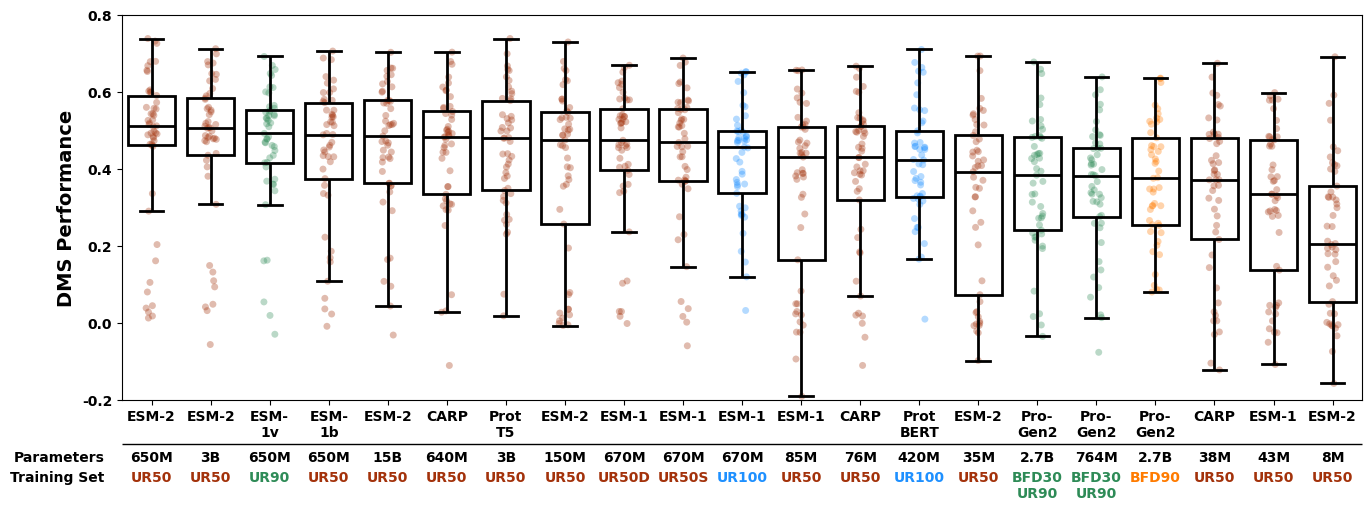

In [13]:
model_info = pd.read_csv("model_info_2.csv")
model_to_base_str = dict(zip(model_info["model_string"].values, model_info["base_string"].values))
model_to_params_str = dict(zip(model_info["model_string"].values, model_info["params_string"].values))
model_to_dataset_str = dict(zip(model_info["model_string"].values, model_info["dataset_string"].values))

x = []
data = []
x_ticklabels = []

my_pal = []

dataset_str_list = []
params_str_list = []

model_to_median = {}

corr_df_plotting = corr_df.drop(columns = ["carp_600k", "prott5_xl_bfd", "protbert_bfd"])
# corr_df_plotting = corr_df


model_to_ci = {}
for c in corr_df_plotting.columns:
    model_to_median[c] = np.median(corr_df_plotting[c])
    model_to_ci[c] = mean_confidence_interval(corr_df_plotting[c])
    
model_to_median = sort_dict_by_value(model_to_median, reverse = True)

for i, (m_name, median_val) in enumerate(model_to_median.items()):
    x.append(i)
    print(m_name)
    label_str = (
        model_to_base_str[m_name]
    )
    
    params_str_list.append(model_to_params_str[m_name] )
    dataset_str_list.append(model_to_dataset_str[m_name].replace("UR", "UR ").replace("-", "").replace("/", "\n"))
    x_ticklabels.append(label_str)
    data.append(corr_df[m_name].values)
    my_pal.append(model_to_color[m_name])


fig, ax = plt.subplots(figsize = (16,5))

sns.boxplot(
    data, 
    color = "white", 
    boxprops=dict(linewidth=2, facecolor=(0, 0, 0, 0), edgecolor='black', zorder = 100),
    medianprops=dict(linewidth=2, color='black', zorder = 100),
    whiskerprops=dict(linewidth=2, color='black', zorder = 100),
    capprops = dict(linewidth=2, color='black', zorder = 100),
    showfliers = False
)


sns.stripplot(
    data, 
    zorder = 1, 
    alpha = 0.33,
    palette = my_pal
)

string_replacements = {
    "ProtBERT" : "Prot\nBERT",
    "ESM-1v" : "ESM-\n1v",
    "ESM-1b" : "ESM-\n1b",
    "ProtT5" : "Prot\nT5",
    "PG2" : "Pro-\nGen2"
}

x_ticklabels = list(map(lambda x : string_replacements[x] if x in string_replacements.keys() else x, x_ticklabels))

for i, (m_name, _) in enumerate(model_to_median.items()):
    ax.text(i, -0.332, params_str_list[i],  horizontalalignment = "center", fontsize = 10,  verticalalignment = "top", fontweight = "bold")

    ax.text(i, -0.382, dataset_str_list[i].replace(" ", "").replace("BFD100", "BFD\n100"), color = model_to_color[m_name], horizontalalignment = "center", fontsize = 10,  verticalalignment = "top", fontweight = "bold")

r1 = mpatches.Rectangle((-0.5, -0.315), len(data), 0.0001, color = "black", clip_on = False)
ax.add_patch(r1)


ax.text(-0.8, -0.332, "Parameters", horizontalalignment = "right", fontsize = 10, fontweight = "bold", verticalalignment = "top")
ax.text(-0.8, -0.382, "Training Set", horizontalalignment = "right", fontsize = 10,  verticalalignment = "top", fontweight = "bold")


ax.set_xticklabels(x_ticklabels, fontsize = 10, fontweight = "bold")
ax.set_yticks([-0.2,0.0,0.2,0.4,0.6,0.8])
ax.set_ylim(bottom = -0.2)
ax.set_yticklabels([-0.2,0.0,0.2,0.4,0.6,0.8],fontsize = 10, fontweight = "bold")
ax.set_ylabel("DMS Performance", fontsize = 14, fontweight = "bold")





/tmp/ipykernel_1962354/3563796036.py:81: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(x_ticklabels, fontsize = 10, fontweight = "bold")


Text(0, 0.5, 'Average Masked Entropy')

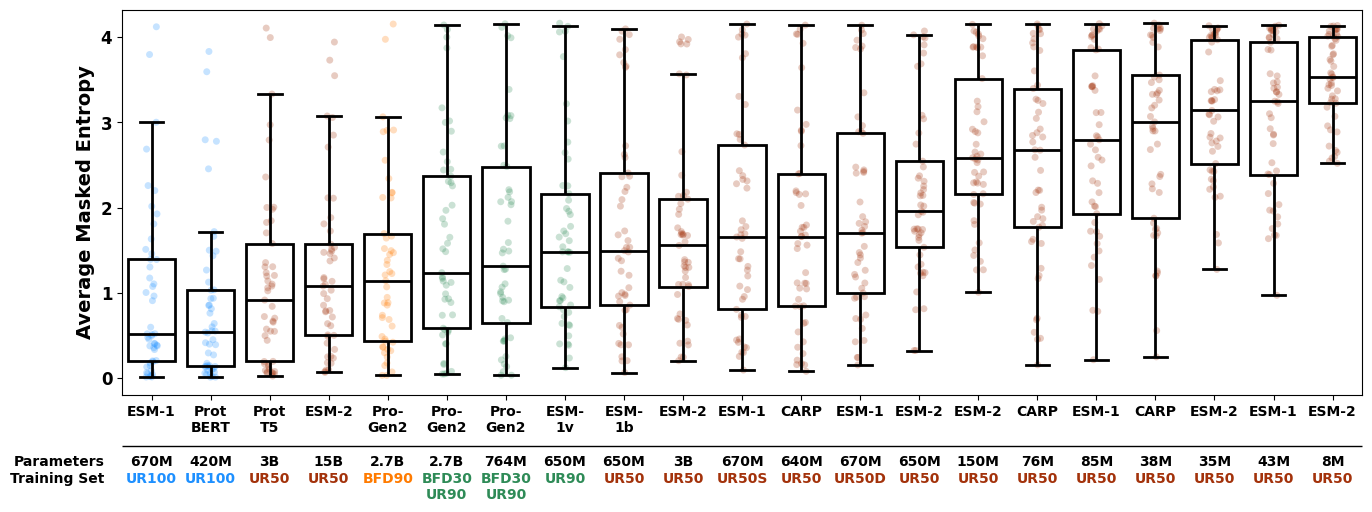

In [14]:



model_to_median_ent = {}

for m in corr_entropy_df.columns:
    if m in ["prott5_xl_bfd", "carp_600k", "protbert_bfd"]:
        continue 
        
    ent_vals = corr_entropy_df[m].values
    model_to_median_ent[m] = np.median(ent_vals)
    

model_to_median_ent = sort_dict_by_value(model_to_median_ent)



x = []
data = []
x_ticklabels = []

my_pal = []
dataset_str_list = []
params_str_list = []

    

for i, (m_name, median_val) in enumerate(model_to_median_ent.items()):
    x.append(i)
    label_str = (
        model_to_base_str[m_name]
    )
    
    params_str_list.append(model_to_params_str[m_name] )
    dataset_str_list.append(model_to_dataset_str[m_name].replace("UR", "UR ").replace("-", "").replace("/", "\n"))
    x_ticklabels.append(label_str)
    data.append(corr_entropy_df[m_name].values)
    my_pal.append(model_to_color[m_name])

    

fig, ax = plt.subplots(figsize = (16,5))

sns.boxplot(
    data, 
    color = "white", 
    boxprops=dict(linewidth=2, facecolor=(0, 0, 0, 0), edgecolor='black', zorder = 100),
    medianprops=dict(linewidth=2, color='black', zorder = 100),
    whiskerprops=dict(linewidth=2, color='black', zorder = 100),
    capprops = dict(linewidth=2, color='black', zorder = 100),
    showfliers = False
)

sns.stripplot(
    data, 
    zorder = 1, 
    alpha = 0.25,
    palette = my_pal
)

string_replacements = {
    "ProtBERT" : "Prot\nBERT",
    "ESM-1v" : "ESM-\n1v",
    "ESM-1b" : "ESM-\n1b",
    "ProtT5" : "Prot\nT5",
    "PG2" : "Pro-\nGen2"
}

x_ticklabels = list(map(lambda x : string_replacements[x] if x in string_replacements.keys() else x, x_ticklabels))

for i, (m_name, _) in enumerate(model_to_median_ent.items()):
    ax.text(i, -0.9, params_str_list[i],  horizontalalignment = "center", fontsize = 10,  verticalalignment = "top", fontweight = "bold")

    ax.text(i, -1.1, dataset_str_list[i].replace(" ", "").replace("BFD100", "BFD\n100"), color = model_to_color[m_name], horizontalalignment = "center", fontsize = 10,  verticalalignment = "top", fontweight = "bold")

r1 = mpatches.Rectangle((-0.5, -0.8), len(data), 0.0001, color = "black", clip_on = False)
ax.add_patch(r1)


ax.text(-0.8, -0.9, "Parameters", horizontalalignment = "right", fontsize = 10, fontweight = "bold", verticalalignment = "top")
ax.text(-0.8, -1.1, "Training Set", horizontalalignment = "right", fontsize = 10,  verticalalignment = "top", fontweight = "bold")


ax.set_xticklabels(x_ticklabels, fontsize = 10, fontweight = "bold")
ax.set_yticks([0,1,2,3,4])
ax.set_ylim(top = np.log2(20))
ax.set_yticklabels([0,1,2,3,4],fontsize = 12, fontweight = "bold")
ax.set_ylabel("Average Masked Entropy", fontsize = 14, fontweight = "bold")



In [15]:
corr_entropy_df.to_csv(supp_table_path + "revisions/corr_entropy_df_dms.csv")

In [16]:
corr_df.to_csv(supp_table_path + "revisions/corr_df_dms.csv")

In [17]:
model_to_display_name_c = {
    "esm_1v" : "ESM-1v (650M) UR90",
    "esm_2_650M" : "ESM-2 (650M) UR50",
    "esm_2": "ESM-2 (3B) UR50",
    "esm_2_15B": "ESM-2 (15B) UR50",
    "prott5_xl" : "ProtT5-XL (3B) UR50",
    "esm_1_UR50D" : "ESM-1 (670M) UR50D",
    "esm_1b": "ESM-1b (650M) UR50",
    "carp_640M": "CARP (640M) UR50",
    "esm_1_UR50": "ESM-1 (650M) UR50S",
    "esm_1_UR100": "ESM-1 (670M) UR100",
    "protbert": "ProtBERT (420M) UR100",
    "protbert_bfd": "ProtBERT (420M) BFD100",
    "esm_2_150M": "ESM-2 (150M) UR50",
    "carp_76M": "CARP(76M) UR50",
    "progen2_bfd": "PG2 (2.7B) BFD90",
    "progen2_large": "PG2 (2.7B) BFD30+UR90",
    "progen2_medium": "PG2 (764M) BFD30+UR90",
    "esm_1_85M": "ESM-1 (85M) UR50",
    "carp_38M": "CARP (38M) UR50",
    "esm_2_35M": "ESM-2 (35M) UR50",
    "esm_1_43M": "ESM-2 (43M) UR50",
    "esm_2_8M": "ESM-2 (8M) UR50"
}

0.5354351650834733
"esm_1v"
"esm_2_650M"
"esm_2"
"esm_2_15B"
"prott5_xl"
"esm_1_UR50D"
"esm_1b"
"carp_640M"
"esm_1_UR50"
"esm_1_UR100"
"protbert"
"esm_2_150M"
"carp_76M"
"progen2_bfd"
"progen2_large"
"progen2_medium"
"esm_1_85M"
"carp_38M"
"esm_2_35M"
"esm_1_43M"
"esm_2_8M"


/tmp/ipykernel_1962354/3241291540.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x, orient = "h", ax = ax, palette = my_pal,  zorder = 100, linewidth=1.2, edgecolor = "black")
/tmp/ipykernel_1962354/3241291540.py:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(labels, fontweight = "bold")


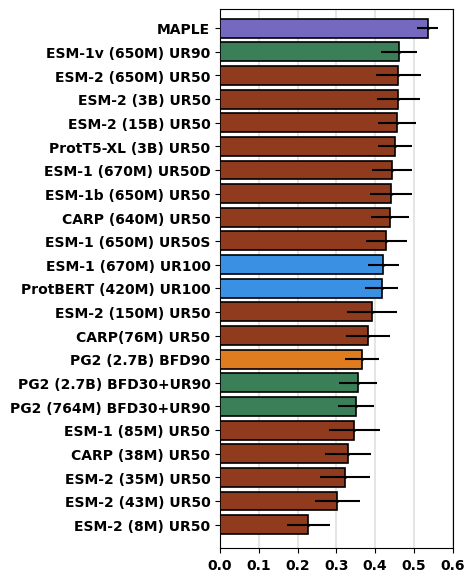

In [18]:
maple_details = pd.read_csv(supp_table_path + "entropy_optimal_model_choices_DMS.csv")
maple_mean, maple_ci_l, maple_ci_h = mean_confidence_interval(maple_details["Optimal Model Performance"].values)

print(maple_mean)
my_pal = []

dataset_str_list = []
params_str_list = []
labels = []
model_to_mean = {}

# were not able to confirm BFD training set w/ original authors "bfd100" different from BFD 90 we do have 

corr_df_plotting = corr_df.drop(columns = ["carp_600k", "prott5_xl_bfd", "protbert_bfd"])
# corr_df_plotting = corr_df


model_to_ci = {}
for c in corr_df_plotting.columns:
    model_to_mean[c] = np.mean(corr_df_plotting[c])
    model_to_ci[c] = mean_confidence_interval(corr_df_plotting[c])
    
model_to_mean = sort_dict_by_value(model_to_mean, reverse = True)

y_val = 0 

x = []
y = []
model_list = []
err_vals = []
err_vals.append([maple_mean - maple_ci_l, maple_ci_h - maple_mean])
    
y.append(y_val)
x.append(np.mean(maple_details["Optimal Model Performance"].values))

labels.append("MAPLE")
my_pal.append("slateblue")

for k, v in model_to_mean.items():
    y_val += 1
    y.append(y_val)
    x.append(v)
    err_vals.append([v - model_to_ci[k][1], model_to_ci[k][2] - v])
    my_pal.append(model_to_color[k])
    labels.append(model_to_display_name_c[k])
    print("\"" + k + "\"")
    
fig, ax = plt.subplots(figsize = (3,7))

sns.barplot(x, orient = "h", ax = ax, palette = my_pal,  zorder = 100, linewidth=1.2, edgecolor = "black")
ax.set_xticks([0.,0.1,0.2,0.3,0.4,0.5,0.6])
ax.set_xticklabels(ax.get_xticklabels(), fontweight = "bold")
ax.set_xlim(left = -0.0, right = 0.6)

ax.set_ylim(top = -0.8, bottom = 22)

ax.set_yticklabels(labels, fontweight = "bold")

ax.scatter(x, y, color = "black", s = 1)
ax.errorbar(x, y, xerr = np.array(err_vals).T, fmt = ".", zorder = 1000, markersize = 1, color = "black")
for x_val in ax.get_xticks():
    ax.axvline(x = x_val, zorder = 0, color = "black", alpha = 0.1)


In [19]:
# export table 
data_df_out = pd.DataFrame({
    "model" : labels,
    "mean" : x,
    "ci_upper" : x + np.asarray(err_vals)[:, 0],
    "ci_lower" : x - np.asarray(err_vals)[:, 0] 
})

data_df_out.to_csv(data_output_path + "fig_4/data_4f.csv")


In [20]:
with open("../all_dms_id_aligned_hsps.pkl", "rb") as f:
    all_hsp_dfs = pickle.load(f)
f.close()

In [21]:

PCT_IDENT = 0.0
GAP_PCT = 0.75
ALN_FRAC = 0.75  


bfd_hom_counts = {}

db_dfs = all_hsp_dfs["BFD"]

for k, dfc in db_dfs.items():
    dfc_2 = dfc.loc[
        (dfc["percent_identity"] >= PCT_IDENT) & 
        (dfc["alignment_frac"] >= ALN_FRAC) & 
        (dfc["percent_gaps"] <= GAP_PCT) &
        (dfc["evalue"] < 1e-5)
    ]
    
    bfd_hom_counts[k] = len(dfc_2)
    


In [22]:
hom_counts = pd.read_csv(llm_review_path + "figure_panels/submission/table_csvs/homologs_all_datasets_DMS.csv")
ur_50_counts = dict(zip(hom_counts["Identifier"].values, hom_counts["UniRef50"].values))
ur_90_counts = dict(zip(hom_counts["Identifier"].values, hom_counts["UniRef90"].values))
ur_100_counts = dict(zip(hom_counts["Identifier"].values, hom_counts["UniRef100"].values))

hom_df_dms = pd.DataFrame({"UniRef50" : ur_50_counts, "BFD" : bfd_hom_counts, "UniRef90" : ur_90_counts, "UniRef100" : ur_100_counts})
hom_df_dms = hom_df_dms.dropna() # contains more than the 49 used proteins in BFD, dropping these 
hom_df_dms.to_csv(supp_table_path + "revisions/r_hom_counts_dms.csv")


In [23]:
hom_counts = pd.read_csv(llm_review_path + "figure_panels/submission/table_csvs/homologs_all_datasets_DMS.csv")
ur_50_counts = dict(zip(hom_counts["Identifier"].values, hom_counts["UniRef50"].values))
ur_90_counts = dict(zip(hom_counts["Identifier"].values, hom_counts["UniRef90"].values))
ur_100_counts = dict(zip(hom_counts["Identifier"].values, hom_counts["UniRef100"].values))


ur_50_models = [
    "esm_2_650M",
    "esm_1_UR50D",
    "esm_1_85M",
    "esm_2_150M",
    "esm_2_8M",
    "esm_1_43M",
    "esm_1b",
    "esm_1_UR50",
    "esm_2_15B",
    "esm_2",
    "esm_2_35M",
    "prott5_xl",
    "carp_640M",
    "carp_76M", 
    "carp_38M",
    "carp_600k",
]


ur_90_models = [
    "esm_1v"
]

ur_100_models = [
    'protbert',
    'esm_1_UR100'
]


bfd_models = [
    "prott5_xl_bfd",
    "protbert_bfd",
    "progen2_bfd"
]

model_to_plot_info = {}

for model in corr_df.columns:
    res_col = corr_df[model].to_dict()
    
    x = []
    y = []
    
    if model in ur_50_models:
        
        for k, v in res_col.items():
            x.append(v)
            y.append(ur_50_counts[k])
            ds_str = "UR50"
            
    elif model in ur_90_models:
        for k, v in res_col.items():
            x.append(v)
            y.append(ur_90_counts[k])
            ds_str = "UR90"
            
    elif model in ["progen2_large", "progen2_medium"]:
        for k, v in res_col.items():
            x.append(v)
            y.append(ur_90_counts[k] + bfd_hom_counts[k])
            ds_str = "UR90_BFD"
        
            
    elif model in ur_100_models:
        
        for k, v in res_col.items():
            x.append(v)
            y.append(ur_100_counts[k])
            ds_str = "UR100"
            
    elif model in bfd_models:
        
        for k, v in res_col.items():
            x.append(v)
            y.append(bfd_hom_counts[k])
            ds_str = "BFD"

    corr, p = scipy.stats.spearmanr(x,y)
        
    model_to_plot_info[model] = {"corr" : corr, "p" : p, "ds_str" :ds_str }
        
    

In [24]:
model_to_base_str = {
 'esm_1_85M' : "ESM-1",
 'carp_76M': "CARP",
 'esm_1_43M': "ESM-1",
 'esm_2_150M': "ESM-2",
 'carp_38M' : "CARP",
 'esm_2_35M': "ESM-2",
 'esm_1_UR50': "ESM-1",
 'esm_1_UR50D': "ESM-1",
 'esm_1b': "ESM-1b",
 'carp_640M' : "CARP",
 'esm_2_650M' : "ESM-2",
 'prott5_xl' : "Prot-T5 XL",
 'esm_2' : "ESM-2",
 'esm_2_8M' : "ESM-2",
 'esm_2_15B' : "ESM-2",
 'carp_600k' : "CARP",
 'protbert_bfd': "ProtBERT",
 'prott5_xl_bfd' : "Prot-T5 XL",
 'progen2_bfd' : "Progen2",
 'progen2_medium': "Progen2",
 'progen2_large': "Progen2",
 'esm_1v' : "ESM-1v",
 'esm_1_UR100' : "ESM-1",
 'protbert' : "ProtBERT"
}




0 0.6274139648461168
1 0.586545575333086
2 0.5809842089698896
3 0.5374116688398918
4 0.5348605833521869
5 0.518992831618663
6 0.5058802522118605
7 0.49766575694145104
8 0.4534299345846499
9 0.4368478789145688
10 0.42506186396137263
11 0.34730477829613055
12 0.34271282441826195
13 0.3351105896649016
14 0.3310798745943281
15 0.5288775510204081
16 0.42846938775510196
17 0.3993979439550624
18 0.36081133091132317
19 0.3028571428571428
20 0.17877551020408164


Text(-0.8, -0.17, 'Training Set')

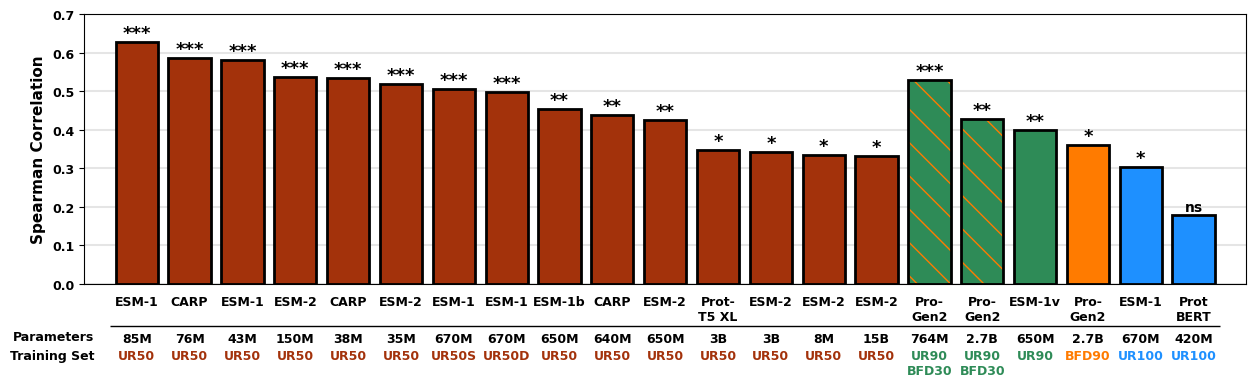

In [25]:
fig, ax = plt.subplots(figsize = (15, 3.5))
plot_df = pd.DataFrame(model_to_plot_info)

# skipped these, could not verify the BFD training data "BFD100" ... 600k model too 
# unreliable to be included in analyses

plot_df = plot_df.drop(columns = ["prott5_xl_bfd", "carp_600k", "protbert_bfd"]).T

x = []
y = []
stars = []
color_dict = {"UR50" : ur_50_color, "UR90" : ur_90_color, "UR100" : ur_100_color, "BFD" : bfd_color, "UR90_BFD" : ur_90_color}
model_list = []
colors = []
hatch_list = []
p_list = []

ur_50_sub = plot_df.loc[plot_df["ds_str"] == "UR50"].sort_values(by = "corr", ascending = False)
bfd_sub = plot_df.loc[plot_df["ds_str"] == "BFD"].sort_values(by = "corr", ascending = False)
ur_90_sub = plot_df.loc[plot_df["ds_str"] == "UR90"].sort_values(by = "corr", ascending = False)
ur_90_bfd_sub = plot_df.loc[plot_df["ds_str"] == "UR90_BFD"].sort_values(by = "corr", ascending = False)
ur_100_sub = plot_df.loc[plot_df["ds_str"] == "UR100"].sort_values(by = "corr", ascending = False)

plot_df = pd.concat([ur_50_sub, ur_90_bfd_sub, ur_90_sub, bfd_sub, ur_100_sub, ])


model_to_ds_shorthand_2 = dict(zip(plot_df.index.values, plot_df["ds_str"].values))

model_to_ds_shorthand_2["esm_1_UR50"] = "UR50S"
model_to_ds_shorthand_2["esm_1_UR50D"] = "UR50D"
model_to_ds_shorthand_2["progen2_medium"] = "UR90\nBFD30"
model_to_ds_shorthand_2["progen2_large"] = "UR90\nBFD30"
model_to_ds_shorthand_2["progen2_bfd"] = "BFD90"
model_to_ds_shorthand_2["protbert_bfd"] = "BFD\n100"
model_to_ds_shorthand_2["protbert"] = "UR100"
model_to_ds_shorthand_2["esm_1_UR100"] = "UR100"
for c, (index, row) in enumerate(plot_df.iterrows()):
    x.append(c)
    y.append(row["corr"])
    stars.append(p_val_to_stars(row["p"]))
    colors.append(color_dict[row["ds_str"]])
    if index in ["progen2_large", "progen2_medium"]:
        hatch_list.append("\\")
    else:
        hatch_list.append("")
        
    model_list.append(index)
    
bars  = ax.bar(x, y, color = colors, hatch = hatch_list, edgecolor = "black", linewidth = 2, zorder = 100)

for bar in bars:
    bar._hatch_color = to_rgba(bfd_color)  
    
for i, m in enumerate(model_list):
    star_str = stars[i]
    y_pos = y[i]
    
    print(i, y_pos)
    
    if star_str == "ns":
        fs = 10
    else:
        fs= 13
    ax.text(i, y_pos + 0.01, star_str, horizontalalignment = "center", fontsize = fs, fontweight = "bold")
    
    bs = model_to_base_str[m]
    
#     if "Prot-T5" in bs:
#         bs = "Prot\nT5-XL"
    
    bs = bs.replace("BERT", "\nBERT").replace("Progen2", "Pro-\nGen2").replace("T5", "\nT5").replace("PG2", "Pro-\nGen2")
    
    ax.text(i, -0.03, bs, horizontalalignment = "center", verticalalignment = "top", fontweight = "bold", fontsize = 9)
    ax.text(i, -0.125, model_to_params_str[m], fontsize = 9, horizontalalignment = "center", verticalalignment = "top", fontweight = "bold")
    ax.text(i, -0.17, model_to_ds_shorthand_2[m], fontsize = 9 , horizontalalignment = "center", verticalalignment = "top", fontweight = "bold", color = colors[i])

ax.set_xlim(left = -1, right  = np.max(x) + 1)
ax.set_ylim(top=0.7)

ax.set_yticks([0,0.1,0.2,0.3,0.4,0.5,0.6,0.7])
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold", fontsize = 9)

for y_val in ax.get_yticks():
    ax.axhline(y = y_val, color = "black", alpha = 0.1, zorder = 1)
    
ax.set_ylabel("Spearman Correlation", fontweight = "bold", fontsize = 11)
ax.set_xticks([])

r1 = mpatches.Rectangle((-0.5, -0.11), len(data), 0.0001, color = "black", clip_on = False)
ax.add_patch(r1)


ax.text(-0.8, -0.122, "Parameters", horizontalalignment = "right", fontsize = 9, fontweight = "bold", verticalalignment = "top")
ax.text(-0.8, -0.17, "Training Set", horizontalalignment = "right", fontsize = 9,  verticalalignment = "top", fontweight = "bold")



In [26]:
# data export 

data_export_df = plot_df.drop(columns = "ds_str")
lst_a = list(map(lambda x: model_to_display_name_c[x], data_export_df.index.values))
data_export_df.index = lst_a

data_export_df.to_csv(data_output_path + "fig_3/data_3c.csv")


In [27]:
model_to_base_str = {
     'esm_1_85M' : "ESM-1",
     'carp_76M': "CARP",
     'esm_1_43M': "ESM-1",
     'esm_2_150M': "ESM-2",
     'carp_38M' : "CARP",
     'esm_2_35M': "ESM-2",
     'esm_1_UR50': "ESM-1",
     'esm_1_UR50D': "ESM-1",
     'esm_1b': "ESM\n1b",
     'carp_640M' : "CARP",
     'esm_2_650M' : "ESM-2",
     'prott5_xl' : "Prot\nT5",
     'esm_2' : "ESM-2",
     'esm_2_8M' : "ESM-2",
     'esm_2_15B' : "ESM-2",
     'carp_600k' : "CARP",
     'protbert_bfd': "Prot\nBERT",
     'progen2_bfd' : "PG2",
     'progen2_medium': "PG2",
     'progen2_large': "PG2",
     'esm_1v' : "ESM\n1v",
     'esm_1_UR100' : "ESM-1",
     'protbert' : "Prot\nBERT"
}

model_to_ds_shorthand_2 = {
     'esm_1_85M': 'UR50',
     'carp_76M': 'UR50',
     'esm_1_43M': 'UR50',
     'esm_2_150M': 'UR50',
     'carp_38M': 'UR50',
     'esm_2_35M': 'UR50',
     'esm_1_UR50': 'UR50S',
     'esm_1_UR50D': 'UR50D',
     'esm_1b': 'UR50',
     'carp_640M': 'UR50',
     'esm_2_650M': 'UR50',
     'prott5_xl': 'UR50',
     'esm_2': 'UR50',
     'esm_2_8M': 'UR50',
     'esm_2_15B': 'UR50',
     'protbert_bfd': 'BFD\n100',
     'progen2_bfd': 'BFD90',
     'progen2_medium': 'UR90\nBFD30',
     'progen2_large': 'UR90\nBFD30',
     'esm_1v': 'UR90',
     'esm_1_UR100': 'UR100',
     'protbert': 'UR100'
}

model_to_params_str = {
     'esm_1_43M': '43M',
     'esm_1_85M': '85M',
     'esm_1b': '650M',
     'esm_1_UR100': '670M',
     'esm_1_UR50D': '670M',
     'esm_1_UR50': '670M',
     'esm_1v': '650M',
     'esm_2': '3B',
     'esm_2_150M': '150M',
     'esm_2_15B': '15B',
     'esm_2_35M': '35M',
     'esm_2_650M': '650M',
     'esm_2_8M': '8M',
     'protbert': '420M',
     'protbert_bfd': '420M',
     'carp_640M': '640M',
     'carp_38M': '38M',
     'carp_76M': '76M',
     'progen2_large': '2.7B',
     'progen2_medium': '764M',
     'progen2_bfd': '2.7B',
     'prott5_xl': '3B',
}

Text(0.5, 1.0, 'ESM-1 (670M) UR100\nPerformance Relationship to Other Models\nDMS Proteins')

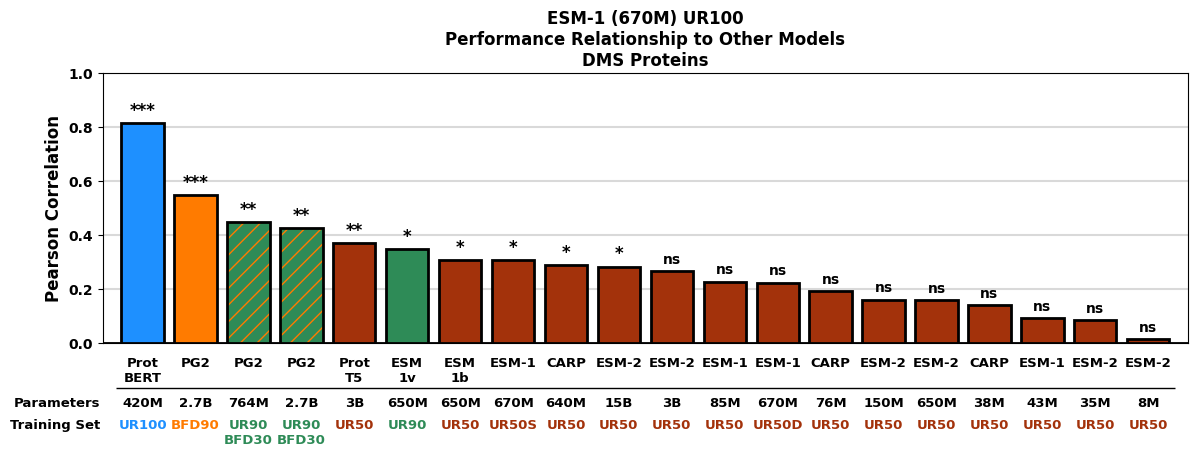

In [28]:
## correlation with UR100 model

esm_1_ur100_res = corr_df["esm_1_UR100"].to_dict()
plotting_info = []

for m in corr_df.columns:
    # skipped these, could not verify the BFD training data... 600k model too 
    # unreliable to be included in analyses
    
    if m in ["carp_600k", "prott5_xl_bfd", "protbert_bfd"]:
        continue
    
    if m == "esm_1_UR100":
        continue 
        
    x1 = []
    x2 = []
    d1 = corr_df[m].to_dict()
    
    for k,v in esm_1_ur100_res.items():
        x1.append(v)
        x2.append(d1[k])
        
    corr, p = scipy.stats.pearsonr(x1,x2)
    
    plotting_info.append([m, corr, p])
    
    
plotting_info = pd.DataFrame(plotting_info, columns = ["model", "corr", "p"])   

plotting_info["color"] = plotting_info["model"].apply(lambda x : model_to_color[x])
plotting_info["df_str"] = plotting_info["model"].apply(lambda x : model_to_ds_shorthand_2[x])
plotting_info = plotting_info.sort_values(by = "corr", ascending = False)
fig, ax = plt.subplots(figsize = (14, 3.5))

x = []
y = []
stars_list = []
m_list = []
color_list = []
hatch_list = []

for i, (index, row) in enumerate(plotting_info.iterrows()):
    model = row["model"]
    x.append(i)
    y.append(row["corr"])
    color_list.append(row["color"])
    stars_list.append(p_val_to_stars(row["p"]))
    
    if model in ["progen2_medium", "progen2_large"]:
        hatch_list.append("//")
    else:
        hatch_list.append("")
        
bars  = ax.bar(x, y,  edgecolor = "black", linewidth = 2, zorder = 100, hatch = hatch_list, color = color_list)

for bar in bars:
    bar._hatch_color = to_rgba(bfd_color) 
    
ax.axhline(y = 0,  color = "black", linewidth = 2)

for i, (index, row) in enumerate(plotting_info.iterrows()):
    
    y_val = row["corr"]
    star_pos = y_val + 0.03
    if y_val < 0:
        star_pos = y_val - 0.05
        
    stars = stars_list[i]
    
    if stars == "ns":
        fs = 10
    else:
        fs = 12
    
    ax.text(i, star_pos, stars, horizontalalignment = "center", fontsize = fs, fontweight = "bold")
    
    ax.text(i, -0.05, model_to_base_str[row["model"]], fontsize = 9.5, horizontalalignment = "center", verticalalignment = "top", fontweight="bold")
    ax.text(i, -0.2, model_to_params_str[row["model"]], fontsize = 9.5, horizontalalignment = "center", verticalalignment = "top", fontweight="bold")
    
    c = row["color"]
    ax.text(i, -0.28, model_to_ds_shorthand_2[row["model"]], color = c, fontsize = 9.5, horizontalalignment = "center", verticalalignment = "top", fontweight="bold")

ax.set_xlim(left = -0.75, right = len(plotting_info) - 0.25)
ax.set_yticks([0,0.2,0.4,0.6,0.8,1.0])
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")

for y_val in ax.get_yticks():
    ax.axhline(y = y_val, color = "black", alpha = 0.15, zorder = 1)
    
ax.set_xticks([])

r1 = mpatches.Rectangle((-0.5, -0.17), len(plotting_info), 0.0001, color = "black", clip_on = False)
ax.add_patch(r1)


ax.text(-0.8, -0.2, "Parameters", horizontalalignment = "right", fontsize = 9.5, fontweight = "bold", verticalalignment = "top")
ax.text(-0.8, -0.28, "Training Set", horizontalalignment = "right", fontsize = 9.5,  verticalalignment = "top", fontweight = "bold")

ax.set_ylabel("Pearson Correlation", fontweight = "bold", fontsize = 12)

ax.set_title("ESM-1 (670M) UR100\nPerformance Relationship to Other Models\nDMS Proteins", fontweight = "bold", fontsize = 12)
      

UniRef50
UniRef90
UniRef100
BFD


Text(0.5, 1.0, 'DMS Proteins')

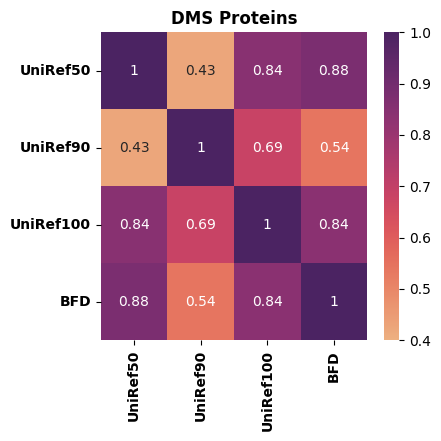

In [29]:
# bfd_counts

labels = ["UniRef50","UniRef90", "UniRef100",  "BFD"]

counts_list = [ur_50_counts, ur_100_counts, ur_90_counts, bfd_hom_counts ]
data = [] 

for i , ds_str_i in enumerate(labels):
    c_i = counts_list[i]
    print(ds_str_i)
    lst = []
    for j, ds_str_j in enumerate(labels):
        x1 = []
        x2 = []
        c_j = counts_list[j]
        
        for k_i, v_i in c_i.items():
            if k_i in c_j.keys():
                x1.append(v_i)
                x2.append(c_j[k_i])
                
        corr, p = scipy.stats.spearmanr(x1,x2)
        lst.append(corr)
    data.append(lst)
    
    
fig, ax = plt.subplots(figsize = (4.3,4))


sns.heatmap(data, annot = True,vmin=0.4, vmax=1, cmap = "flare")

ax.set_yticklabels(labels, rotation = 0, fontweight = "bold")
ax.set_xticklabels(labels, rotation = 90, fontweight = "bold")
ax.set_title("DMS Proteins", fontweight = "bold")